In [30]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit

### Take data

In [31]:
h1 = np.array([0,4,8,13,19,26,34,43,53,65,76,91,106,122])  
h = np.array([122-x for x in h1])
sigma_h = np.array([1e-16, 0.5, 1, 1, 1.5, 1.5, 1.5, 2, 2, 2.5, 2.5, 2.5, 3, 3])  
t = np.array([0, 0.100, 0.135, 0.170, 0.200, 0.240, 0.270, 0.305, 0.340, 0.370, 0.405, 0.440, 0.470, 0.505]) 

In [32]:
len(sigma_h)

14

In [33]:
# Conversione in m.
h = h / 100.0
sigma_h = sigma_h / 100.0

don't start sigma_x with 0,ca use trouble and won't fit  
instead put a small value 1e-6

In [34]:
def parabola(t, a, v0, h0):
    """Modello di fit quadratico"""

    return 0.5 * a * t**2.0 + v0 * t + h0


-9.822877568697676 0.0989344324639507 0.07976942814148365 0.01627499611248316 1.22 3.7778459496897083e-19


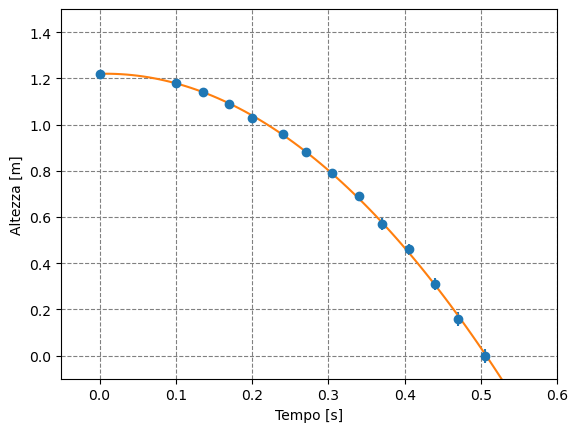

In [35]:
plt.figure('Legge oraria')
# Grafico dei punti sperimentali
plt.errorbar(t, h, sigma_h, fmt='o')
popt, pcov = curve_fit(parabola, t, h, sigma=sigma_h, maxfev=10000)
a_hat, v0_hat, h0_hat = popt
sigma_a, sigma_v0, sigma_h0 = np.sqrt(np.diagonal(pcov))
print(a_hat, sigma_a, v0_hat, sigma_v0, h0_hat, sigma_h0)

# Grafico del modello di fit.
x = np.linspace(0.0, 0.7, 100)
plt.plot(x, parabola(x, *popt))
plt.xlabel('Tempo [s]')
plt.ylabel('Altezza [m]')
plt.xlim(-0.05,0.6)
plt.ylim(-0.1,1.5)
plt.grid(ls='dashed', which='both', color='gray')
plt.show()

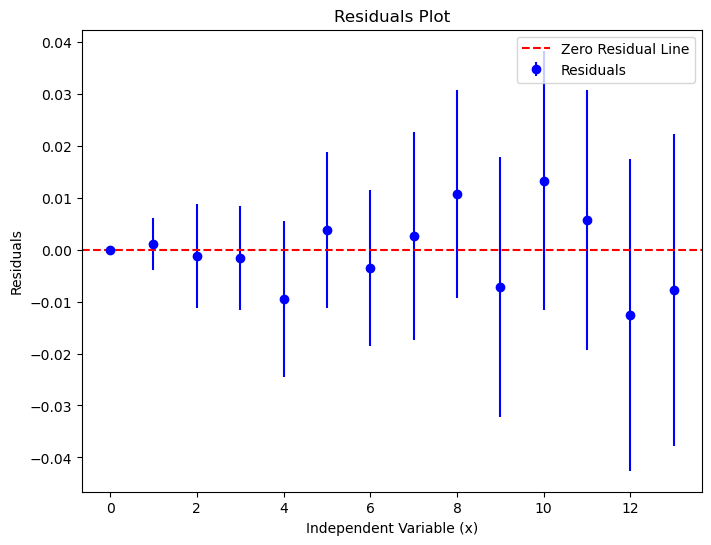

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Calculate residuals: y-y_pred
residuals = h - parabola(t, a_hat, v0_hat, h0_hat)

# Plot the residuals - remember to put the y error of the thing
plt.figure(figsize=(8, 6))
plt.errorbar(range(len(residuals)), residuals, yerr=sigma_h, color='blue', label='Residuals', fmt='o')

plt.axhline(y=0, color='red', linestyle='--', label='Zero Residual Line')
plt.xlabel('Independent Variable (x)')
plt.ylabel('Residuals')
plt.title('Residuals Plot')
plt.legend()
plt.show()

### Chi-squared test

In [37]:
print(residuals)

[ 0.          0.00113745 -0.0012579  -0.00162022 -0.00949633  0.00375421
 -0.00349386  0.00255692  0.01064072 -0.00713872  0.01329213  0.005756
 -0.0125548  -0.00774389]


In [50]:
# Compute Chi-squared using my data  

chi = np.sum((residuals/sigma_h)**2) 

print(chi)

1.569933198704251


In [51]:
# Degrees of freedom: 14 points - 3 fit parameters

dof = 11

In [52]:
chi_reduced = chi/dof

print(chi_reduced)

0.14272119988220464


In [53]:
from scipy.stats import chi2 as chi2_dist

# Correcting the p-value calculation
p_value = 1 - chi2_dist.cdf(chi, dof)

print(p_value)

0.9995252916986862


### Try

In [54]:
# Covariances
cov_av0 = pcov[0, 1]
cov_ah0 = pcov[0, 2]
cov_v0h0 = pcov[1, 2]

# Propagated uncertainty on h(t) for each t
sigma_h_pred = np.sqrt(
    (0.5 * t**2)**2 * sigma_a**2 +
    (t)**2 * sigma_v0**2 +
    sigma_h0**2 +
    2 * (0.5 * t**2) * t * cov_av0 +
    2 * (0.5 * t**2) * cov_ah0 +
    2 * t * cov_v0h0
)

# Now sigma_h_pred gives the uncertainty on the predicted height at each time t


In [55]:
chi2 = np.sum((residuals/sigma_h_pred)**2) 
print(chi2)

102.22439147234006


this is much worse